In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Random number generator with a fixed seed, so we get the same numbers every run
rng = np.random.default_rng(42)

tokens = ["I", "love", "learning", "AI"]
n_tokens = len(tokens)
d_model = 8  # size of each token vector

# Toy embeddings: one random vector of 8 numbers for each token
X = rng.standard_normal((n_tokens, d_model))

print("Tokens :", tokens)
print("X shape:", X.shape)
print(np.round(X, 2))

Tokens : ['I', 'love', 'learning', 'AI']
X shape: (4, 8)
[[ 0.3  -1.04  0.75  0.94 -1.95 -1.3   0.13 -0.32]
 [-0.02 -0.85  0.88  0.78  0.07  1.13  0.47 -0.86]
 [ 0.37 -0.96  0.88 -0.05 -0.18 -0.68  1.22 -0.15]
 [-0.43 -0.35  0.53  0.37  0.41  0.43  2.14 -0.41]]


In [2]:
d_k = d_model  # single head uses the full vector size

# Weight matrices, scaled down by sqrt(d_model) like real models do at the start
# (in a real model these are learned during training)
scale = np.sqrt(d_model)
W_Q = rng.standard_normal((d_model, d_k)) / scale
W_K = rng.standard_normal((d_model, d_k)) / scale
W_V = rng.standard_normal((d_model, d_k)) / scale

# Every token's vector times each matrix
Q = X @ W_Q
K = X @ W_K
V = X @ W_V

print("W_Q shape:", W_Q.shape)
print("Q shape  :", Q.shape)
print("K shape  :", K.shape)
print("V shape  :", V.shape)

print("\nQuery vector of 'I':", np.round(Q[0], 2))
print("Key vector of 'AI' :", np.round(K[3], 2))

W_Q shape: (8, 8)
Q shape  : (4, 8)
K shape  : (4, 8)
V shape  : (4, 8)

Query vector of 'I': [-0.34 -0.63  0.18  0.52 -1.4  -0.28  0.28  1.1 ]
Key vector of 'AI' : [-0.35 -0.32 -0.11  0.14  1.05 -0.14 -0.1  -1.06]


In [3]:
def show_matrix(M, title):
    """Print a token-by-token matrix with labels."""
    print(title)
    print(" " * 10 + "".join(f"{t:>10}" for t in tokens))
    for i, row in enumerate(M):
        print(f"{tokens[i]:>10}" + "".join(f"{v:>10.2f}" for v in row))
    print()


# Every query against every key: (4x8) @ (8x4) = (4x4)
scores = Q @ K.T
show_matrix(scores, "Raw scores (Q @ K.T):")

# Scale down by sqrt(d_k)
scaled = scores / np.sqrt(d_k)
show_matrix(scaled, f"Scaled scores (divided by sqrt({d_k}) = {np.sqrt(d_k):.2f}):")

print("Raw range   :", round(scores.min(), 2), "to", round(scores.max(), 2))
print("Scaled range:", round(scaled.min(), 2), "to", round(scaled.max(), 2))

Raw scores (Q @ K.T):
                   I      love  learning        AI
         I      1.27     -0.21     -0.50     -2.25
      love      1.21     -0.23     -0.54     -1.24
  learning     -1.51     -0.14     -0.22     -0.78
        AI      0.75     -1.04      0.52     -1.24

Scaled scores (divided by sqrt(8) = 2.83):
                   I      love  learning        AI
         I      0.45     -0.07     -0.18     -0.80
      love      0.43     -0.08     -0.19     -0.44
  learning     -0.53     -0.05     -0.08     -0.28
        AI      0.27     -0.37      0.18     -0.44

Raw range   : -2.25 to 1.27
Scaled range: -0.8 to 0.45


In [4]:
# Causal mask, the simple way (for both versions)
masked = scaled.copy()  # WITH scaling
masked_unscaled = scores.copy()  # WITHOUT scaling

for i in range(n_tokens):  # i = the token that is looking (query row)
    for j in range(n_tokens):  # j = the token being looked at (key column)
        if j > i:  # j comes AFTER i -> it is the future -> hide it
            masked[i][j] = -np.inf
            masked_unscaled[i][j] = -np.inf
            print(f"'{tokens[i]}' cannot see '{tokens[j]}'  -> set to -inf")

print()
show_matrix(masked, "Masked scores WITH scaling:")
show_matrix(masked_unscaled, "Masked scores WITHOUT scaling:")

'I' cannot see 'love'  -> set to -inf
'I' cannot see 'learning'  -> set to -inf
'I' cannot see 'AI'  -> set to -inf
'love' cannot see 'learning'  -> set to -inf
'love' cannot see 'AI'  -> set to -inf
'learning' cannot see 'AI'  -> set to -inf

Masked scores WITH scaling:
                   I      love  learning        AI
         I      0.45      -inf      -inf      -inf
      love      0.43     -0.08      -inf      -inf
  learning     -0.53     -0.05     -0.08      -inf
        AI      0.27     -0.37      0.18     -0.44

Masked scores WITHOUT scaling:
                   I      love  learning        AI
         I      1.27      -inf      -inf      -inf
      love      1.21     -0.23      -inf      -inf
  learning     -1.51     -0.14     -0.22      -inf
        AI      0.75     -1.04      0.52     -1.24



### Causal mask: why the future is hidden

- GPT predicts the **next** token, so a token may only look at itself and the tokens **before** it.
- Rule: if `j > i` (the key comes after the query), the score is set to **-inf**.
- After softmax, `e^(-inf) = 0`, so future tokens get **exactly 0** attention. This is the all-zero upper triangle in the heatmap.
- **Why it matters in training:** the whole sentence is fed in at once. Without the mask, each position could simply look ahead and **copy the next word**, so training loss would look perfect while the model learns nothing it can use when generating text.
- Bonus: the mask lets every position in a sentence be trained **in parallel** without cheating.

In [5]:
import math


def softmax_row(row):
    """Turn one row of scores into probabilities that add up to 1."""
    # Step 1: e to the power of each score
    exps = []
    for value in row:
        exps.append(math.exp(value))  # e^(-inf) = 0

    # Step 2: add them all up
    total = sum(exps)

    # Step 3: divide each one by the total
    probs = []
    for e in exps:
        probs.append(e / total)
    return probs


# Apply softmax to every row, one by one, for both versions
weights = np.zeros((n_tokens, n_tokens))  # WITH scaling
weights_unscaled = np.zeros((n_tokens, n_tokens))  # WITHOUT scaling

for i in range(n_tokens):
    weights[i] = softmax_row(masked[i])
    weights_unscaled[i] = softmax_row(masked_unscaled[i])

show_matrix(weights, "Attention weights WITH scaling:")
show_matrix(weights_unscaled, "Attention weights WITHOUT scaling:")

# Range of the weights for each token (only the tokens it is allowed to see)
for i in range(n_tokens):
    visible_scaled = []
    visible_unscaled = []
    for j in range(i + 1):  # j = 0 .. i (past tokens + itself)
        visible_scaled.append(weights[i][j])
        visible_unscaled.append(weights_unscaled[i][j])

    print(f"Row '{tokens[i]}' (can see {i + 1} token(s)):")
    print(
        f"   with scaling    -> min {min(visible_scaled):.2f}, max {max(visible_scaled):.2f}"
    )
    print(
        f"   without scaling -> min {min(visible_unscaled):.2f}, max {max(visible_unscaled):.2f}"
    )

Attention weights WITH scaling:
                   I      love  learning        AI
         I      1.00      0.00      0.00      0.00
      love      0.62      0.38      0.00      0.00
  learning      0.24      0.39      0.38      0.00
        AI      0.34      0.18      0.31      0.17

Attention weights WITHOUT scaling:
                   I      love  learning        AI
         I      1.00      0.00      0.00      0.00
      love      0.81      0.19      0.00      0.00
  learning      0.12      0.46      0.42      0.00
        AI      0.48      0.08      0.38      0.07

Row 'I' (can see 1 token(s)):
   with scaling    -> min 1.00, max 1.00
   without scaling -> min 1.00, max 1.00
Row 'love' (can see 2 token(s)):
   with scaling    -> min 0.38, max 0.62
   without scaling -> min 0.19, max 0.81
Row 'learning' (can see 3 token(s)):
   with scaling    -> min 0.24, max 0.39
   without scaling -> min 0.12, max 0.46
Row 'AI' (can see 4 token(s)):
   with scaling    -> min 0.17, max 0.34
   

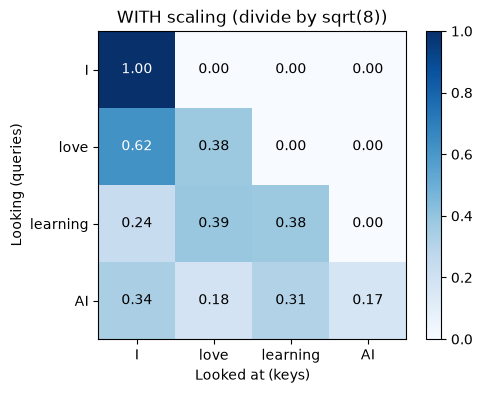

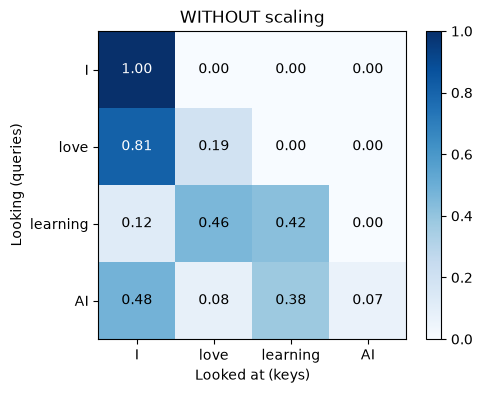

In [6]:
def plot_heatmap(matrix, title):
    """Draw an attention matrix as a colored grid, with each number written inside."""
    fig, ax = plt.subplots(figsize=(5, 4))
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)

    # Token names on both axes
    ax.set_xticks(range(n_tokens))
    ax.set_xticklabels(tokens)
    ax.set_yticks(range(n_tokens))
    ax.set_yticklabels(tokens)
    ax.set_xlabel("Looked at (keys)")
    ax.set_ylabel("Looking (queries)")
    ax.set_title(title)

    # Write each weight inside its box
    for i in range(n_tokens):
        for j in range(n_tokens):
            value = matrix[i][j]
            if value > 0.5:
                color = "white"  # dark box -> white text
            else:
                color = "black"  # light box -> black text
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=color)

    fig.colorbar(image, ax=ax)
    plt.show()


plot_heatmap(weights, f"WITH scaling (divide by sqrt({d_k}))")
plot_heatmap(weights_unscaled, "WITHOUT scaling")

### What the two heatmaps show

**Same Q and K, same causal mask. The only difference is dividing by √dₖ.**

**Both heatmaps:**
- The upper triangle is all **0**: the causal mask stops every token from looking at future tokens.
- The first row (`I`) is **[1, 0, 0, 0]**: the first token can only see itself, so all its attention goes there.

**WITHOUT scaling:**
- Raw dot products are large, because a dot product adds up `d_k` numbers and grows with the dimension.
- Softmax turns large gaps into **almost one-hot** rows: nearly all attention goes to a single token.
- The output for that token becomes almost a **copy of one value vector**, so it gets very little context from the other tokens.
- During training, a saturated softmax gives **near-zero gradients**, so W_Q and W_K stop learning.

**WITH scaling (÷ √dₖ):**
- Scores are pulled back to a normal range (around 1).
- Attention is **spread across several tokens**, so each output mixes information from its context.
- Gradients stay healthy, so the model can keep learning.

> **Takeaway:** without √dₖ, attention stops "paying attention" and starts "copying". That is why real models always scale.

In [7]:
# Output = weighted sum of value vectors (we use the scaled weights, like real models)
output = np.zeros((n_tokens, d_k))

for i in range(n_tokens):  # i = the token that is looking
    for j in range(n_tokens):  # j = the token it looks at
        output[i] += weights[i][j] * V[j]  # weight (a number) x value (a vector)

print("Output shape:", output.shape)
print("\nV of 'I'      :", np.round(V[0], 2))
print("Output of 'I' :", np.round(output[0], 2))
print("\nOutput of 'AI':", np.round(output[3], 2))

# Check: the matrix way gives the same answer
print("\nSame as weights @ V?", np.allclose(output, weights @ V))

# Residual: add the update to the original vectors
X_new = X + output
print("New X shape:", X_new.shape)

Output shape: (4, 8)

V of 'I'      : [ 0.52 -1.33  1.28 -0.25  0.68  1.21  1.39  1.05]
Output of 'I' : [ 0.52 -1.33  1.28 -0.25  0.68  1.21  1.39  1.05]

Output of 'AI': [ 0.21 -0.51  0.85 -0.52  0.46  0.6   0.62  0.89]

Same as weights @ V? True
New X shape: (4, 8)
